In [ ]:
# Resolve the repository root so data/ and output/ paths work from any working directory
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "data").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

# Start

In this note book my primarely goal is to validate NTL using Quartely GDP data...the source of the GDP is the Statistic Center of Iran...here are my steps : 1- make the preperation: import the needed libraries, font, etc 2- reading the Csv file of GDP and NTL from known address 3- Cleaning The Data set so at the end both have one column which I merge base on that 4- at the last task for cleaning make a Log function as another validation system 5- merge the data sets 6- I check the co movement and draw the scatter plot of GDP and NTL and calculate the Pearson Correlation Coeficient. 7- I did step six for non-oil GDP as a robustness check 8- I did two simple regression just to get a coef for these two variable 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from scipy.stats import spearmanr



The next part is for reading the persian and making the plots more readble in the code and the data properly

In [2]:
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10
sns.set_style("whitegrid")
plt.rcParams['font.family'] = 'DejaVu Sans'
sns.set_style("whitegrid")

Reading the data of Quarterly NTL for Iran and National Quarterly GDP of the whole Country will do in the upcoming part

In [3]:
gdp = pd.read_excel(str(ROOT / "data/GDP_per_capita/National_GDP_per_capita_Quarterly_1390_1404.xlsx"))
ntl = pd.read_csv(str(ROOT / "data/Iran_NTL/Iran_NTL_Quarterly_2012_2024.csv"))

# Structure of data

Now we take a look to the structure of this two data set to know them better

In [7]:
print("=== GDP Data ===")
print(gdp.head())
print(f"\nShape: {gdp.shape}")
print(f"Columns: {gdp.columns.tolist()}")

print("\n=== NTL Data ===")
print(ntl.head())
print(f"\nShape: {ntl.shape}")
print(f"Columns: {ntl.columns.tolist()}")

=== GDP Data ===
   Year  Quarter  Population  GDP_total_bilRial  GDP_non_oil_bilRial  \
0  1390        1    75149669       1.939271e+07         1.261731e+07   
1  1390        2    75149669       2.308720e+07         1.667169e+07   
2  1390        3    75149669       2.334147e+07         1.717112e+07   
3  1390        4    75149669       2.283005e+07         1.723897e+07   
4  1391        1    76052006       1.962919e+07         1.452656e+07   

   GDP_per_capita_Rial  GDP_non_oil_per_capita_Rial  \
0         2.580546e+08                 1.678957e+08   
1         3.072163e+08                 2.218464e+08   
2         3.105998e+08                 2.284923e+08   
3         3.037944e+08                 2.293952e+08   
4         2.581022e+08                 1.910082e+08   

   GDP_per_capita_millionRial  GDP_non_oil_per_capita_millionRial  
0                  258.054561                          167.895718  
1                  307.216270                          221.846428  
2              

# Data Cleaning 

first of all cleaning the GDP data and add a common key for merging

In [4]:
# سلول 5: آماده‌سازی GDP

gdp_clean = gdp.copy()

# اطمینان از نوع عددی
gdp_clean['Year'] = pd.to_numeric(gdp_clean['Year'], errors='coerce')
gdp_clean['Quarter'] = pd.to_numeric(gdp_clean['Quarter'], errors='coerce')

# حذف سطرهای ناقص احتمالی
gdp_clean = gdp_clean.dropna(subset=['Year', 'Quarter'])

# ساخت کلید سال-فصل
gdp_clean['year_quarter'] = gdp_clean['Year'].astype(int).astype(str) + "Q" + gdp_clean['Quarter'].astype(int).astype(str)

#display(gdp_clean[['Year', 'Quarter', 'year_quarter']].head())


now Cleaning the NTL data and add the key for merge

In [5]:
# سلول 6: آماده‌سازی NTL

ntl_clean = ntl.copy()

ntl_clean['Shamsi_Year'] = pd.to_numeric(ntl_clean['Shamsi_Year'], errors='coerce')
ntl_clean['Quarter'] = pd.to_numeric(ntl_clean['Quarter'], errors='coerce')

ntl_clean = ntl_clean.dropna(subset=['Shamsi_Year', 'Quarter'])

ntl_clean['year_quarter'] = ntl_clean['Shamsi_Year'].astype(int).astype(str) + "Q" + ntl_clean['Quarter'].astype(int).astype(str)

#display(ntl_clean[['Year', 'Shamsi_Year', 'Quarter', 'year_quarter']].head())


Last cleaning action for make it more readble

In [6]:
# Step 4: Select main variables from GDP and NTL datasets

gdp_vars = [
    'year_quarter',
    'Year',
    'Quarter',
    'GDP_total_bilRial',
    'GDP_non_oil_bilRial',
    'GDP_per_capita_millionRial'
]


ntl_vars = [
    'year_quarter',
    'Year',          
    'Shamsi_Year',   
    'Quarter',
    'Sum_Radiance_sum',
    'Mean_Radiance_avg'
]

# Rename columns to avoid collisions after merge
gdp_sel = gdp_clean[gdp_vars].rename(columns={
    'Year': 'Shamsi_Year_gdp',
    'Quarter': 'Quarter_gdp'
})

ntl_sel = ntl_clean[ntl_vars].rename(columns={
    'Year': 'Year_greg_ntl',
    'Quarter': 'Quarter_ntl'
})


now merge base on the common key

In [7]:
# Step 5: Merge GDP and NTL on year_quarter

df = pd.merge(
    gdp_sel,
    ntl_sel,
    on='year_quarter',
    how='inner',   # inner merge keeps only overlapping quarters
    suffixes=('_gdp', '_ntl')
)

#print(df.shape)
#display(df.head())


for the sake of analisys I make some log variable for NTL data for all the columns

In [8]:
# Step 6: Create log-transformed variables

for col in [
    'GDP_total_bilRial',
    'GDP_per_capita_millionRial',
    'GDP_non_oil_bilRial',
    'Sum_Radiance_sum',
    'Mean_Radiance_avg'
]:
    df[f'log_{col}'] = np.log(df[col])


#display(df[['year_quarter', 'log_GDP_total_bilRial', 'log_Sum_Radiance_sum']].head())


# Validate NTL and Seasonal GDP 

now it is time to see the validation in a plot first we normalized the data and then check the comovement of the variables. it is good to notice that NTL is sum base not mean and we normalized both GDP and NTL.

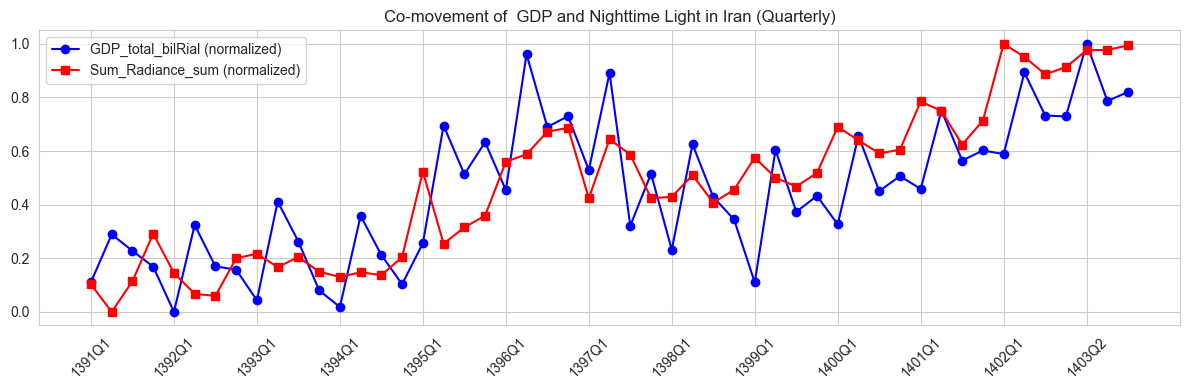

In [13]:
# Step 7: Plot normalized series to visually inspect co-movement

def min_max(series):
    """Normalize a series to the 0-1 range."""
    return (series - series.min()) / (series.max() - series.min())

df_sorted = df.sort_values('year_quarter')

plt.figure(figsize=(12, 4))

plt.plot(
    df_sorted['year_quarter'],
    min_max(df_sorted['GDP_total_bilRial']),
    label='GDP_total_bilRial (normalized)',
    color='blue',
    marker='o'
)

plt.plot(
    df_sorted['year_quarter'],
    min_max(df_sorted['Sum_Radiance_sum']),
    label='Sum_Radiance_sum (normalized)',
    color='red',
    marker='s'
)

plt.xticks(
    ticks=range(0, len(df_sorted), 4),
    labels=df_sorted['year_quarter'].iloc[::4],
    rotation=45
)

plt.title("Co-movement of  GDP and Nighttime Light in Iran (Quarterly)")


plt.legend()
plt.tight_layout()
plt.show();


In this part I use the pearson Correlation and draw the scatter plot of this two variable which show the regression coeffiecient about 0.7. it is important to notice that it is not correct for casual inference to use Total GDP but we should check the non-oil-GDP as so

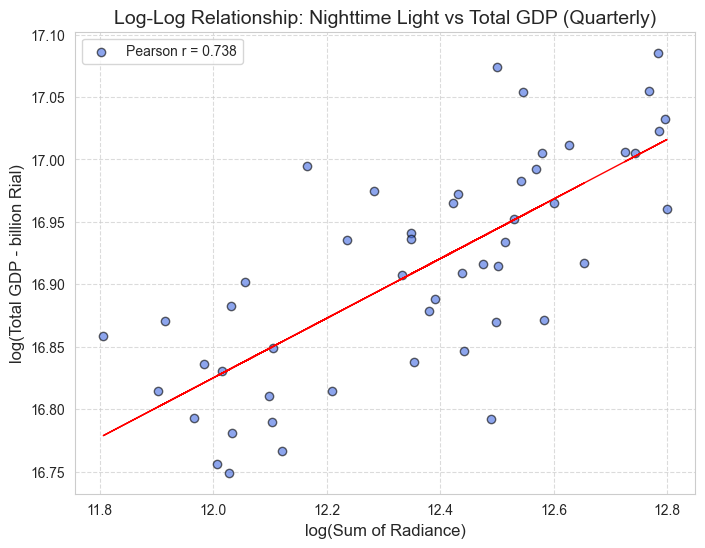

In [14]:
import scipy.stats as stats

# محاسبه ضریب همبستگی پیرسون روی داده‌های لگاریتمی
corr, _ = stats.pearsonr(df['log_Sum_Radiance_sum'], df['log_GDP_total_bilRial'])

plt.figure(figsize=(8, 6))

# رسم نقاط
plt.scatter(
    df['log_Sum_Radiance_sum'], 
    df['log_GDP_total_bilRial'], 
    alpha=0.6, 
    color='royalblue', 
    edgecolors='k',
    label=f'Pearson r = {corr:.3f}'
)

# رسم خط رگرسیون (Trendline)
m, b = np.polyfit(df['log_Sum_Radiance_sum'], df['log_GDP_total_bilRial'], 1)
plt.plot(df['log_Sum_Radiance_sum'], m*df['log_Sum_Radiance_sum'] + b, color='red', linewidth=1)

plt.title('Log-Log Relationship: Nighttime Light vs Total GDP (Quarterly)', fontsize=14)
plt.xlabel('log(Sum of Radiance)', fontsize=12)
plt.ylabel('log(Total GDP - billion Rial)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

plt.show()


now one important problem who NTL make for Iran economic we should use non-oil GDP instead og total GDP so in  the nex part I check the co-movement of NTL and non-oil GDP 

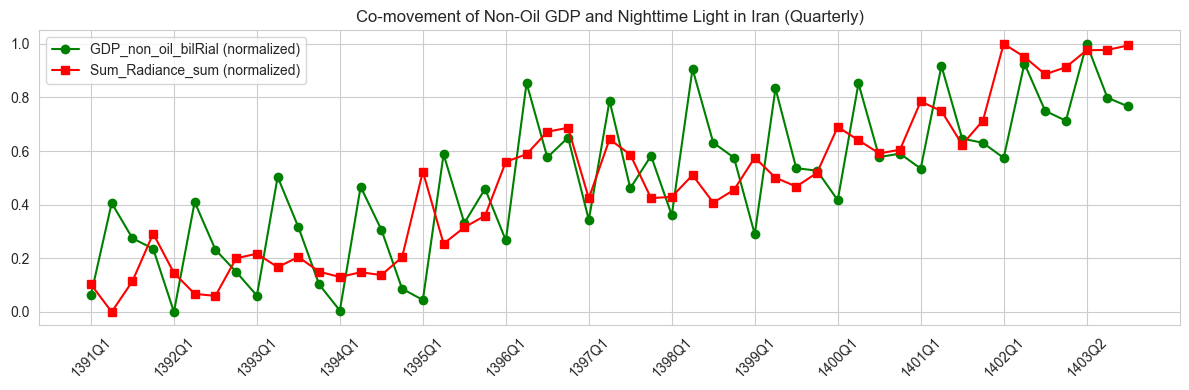

In [15]:
# Step 7b: Plot normalized Non-Oil GDP and NTL to inspect co-movement

def min_max(series):
    """Normalize a series to the 0-1 range."""
    return (series - series.min()) / (series.max() - series.min())

df_sorted = df.sort_values('year_quarter')

plt.figure(figsize=(12, 4))

plt.plot(
    df_sorted['year_quarter'],
    min_max(df_sorted['GDP_non_oil_bilRial']),
    label='GDP_non_oil_bilRial (normalized)',
    color='green',
    marker='o'
)

plt.plot(
    df_sorted['year_quarter'],
    min_max(df_sorted['Sum_Radiance_sum']),
    label='Sum_Radiance_sum (normalized)',
    color='red',
    marker='s'
)

plt.xticks(
    ticks=range(0, len(df_sorted), 4),
    labels=df_sorted['year_quarter'].iloc[::4],
    rotation=45
)

plt.title("Co-movement of Non-Oil GDP and Nighttime Light in Iran (Quarterly)")

plt.legend()
plt.tight_layout()
plt.show();


after drawing the plot it is time to estimate the pearson coeficient for non-oil GDP and NTL. I report it below


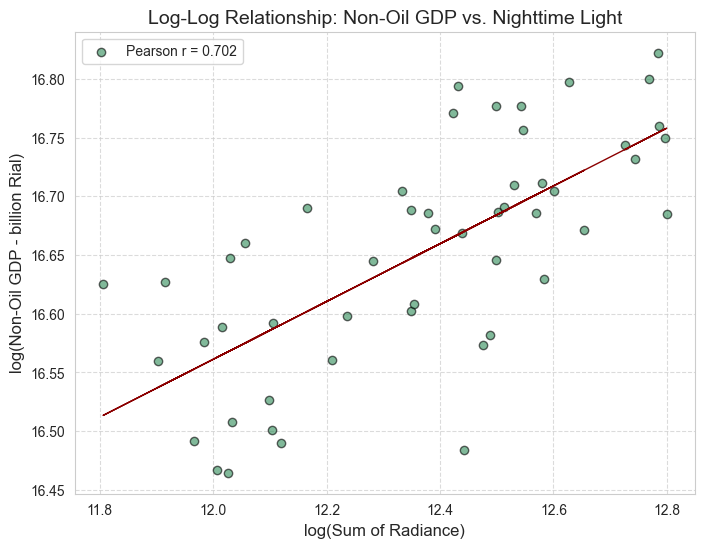

In [16]:
import scipy.stats as stats

# محاسبه همبستگی پیرسون
corr, _ = stats.pearsonr(df['log_Sum_Radiance_sum'], df['log_GDP_non_oil_bilRial'])

plt.figure(figsize=(8, 6))

# نمودار نقاط اسکتر
plt.scatter(
    df['log_Sum_Radiance_sum'], 
    df['log_GDP_non_oil_bilRial'],
    alpha=0.6,
    color='seagreen',
    edgecolors='k',
    label=f'Pearson r = {corr:.3f}'
)

# خط رگرسیون
m, b = np.polyfit(df['log_Sum_Radiance_sum'], df['log_GDP_non_oil_bilRial'], 1)
plt.plot(df['log_Sum_Radiance_sum'], m*df['log_Sum_Radiance_sum'] + b, color='darkred', linewidth=1)

plt.title('Log-Log Relationship: Non-Oil GDP vs. Nighttime Light', fontsize=14)
plt.xlabel('log(Sum of Radiance)', fontsize=12)
plt.ylabel('log(Non-Oil GDP - billion Rial)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

plt.show()


just a simple regression for seeing the coef of this OLS which give a good insite about the data. first regress is for non-oil GDP on NTL

In [17]:
import numpy as np
import statsmodels.api as sm

X = sm.add_constant(df['log_Sum_Radiance_sum'])
y = df['log_GDP_non_oil_bilRial']

model_non_oil = sm.OLS(y, X).fit()
#print(model_non_oil.summary())

second regress is for total GDP on NTL

In [18]:
import numpy as np
import statsmodels.api as sm

X = sm.add_constant(df['log_Sum_Radiance_sum'])
y = df['log_GDP_total_bilRial']

model_total = sm.OLS(y, X).fit()
#print(model_total.summary())



# Trends of GDP for each Province

first of all we read the GDP for each province data

In [9]:
gdp_province = pd.read_csv(str(ROOT / "data/GDP_per_capita/Province_GDP_per_capita.csv"))

Data Cleaning

In [10]:
# 1. Calculate the annual national Total GDP
total_gdp_yearly = gdp_province.groupby('Year')['GDP'].sum().reset_index()
total_gdp_yearly.rename(columns={'GDP': 'Total_GDP'}, inplace=True)

# 2. Merge the annual total back into your main provincial dataframe
df_all_shares = pd.merge(gdp_province, total_gdp_yearly, on='Year')

# 3. Calculate each province's macroeconomic share as a percentage
df_all_shares['GDP_Share_Percent'] = (df_all_shares['GDP'] / df_all_shares['Total_GDP']) * 100

# Inspect the calculated shares for the first few rows
print("Successfully calculated shares for all provinces. Preview:")
print(df_all_shares[['Year', 'نام استان', 'GDP_Share_Percent']].head())

Successfully calculated shares for all provinces. Preview:
   Year       نام استان  GDP_Share_Percent
0  1390           مرکزی           2.011159
1  1390           گیلان           1.937453
2  1390        مازندران           2.941745
3  1390  آذربایجان شرقی           2.991412
4  1390  آذربایجان غربی           1.794943


In [11]:
# Cell 2: Map all 31 Persian province names to English for clean Matplotlib rendering
all_provinces_translation = {
    'تهران': 'Tehran', 'خوزستان': 'Khuzestan', 'اصفهان': 'Isfahan', 
    'خراسان رضوی': 'Razavi Khorasan', 'فارس': 'Fars', 'آذربایجان شرقی': 'East Azerbaijan',
    'مازندران': 'Mazandaran', 'البرز': 'Alborz', 'کرمان': 'Kerman', 
    'بوشهر': 'Bushehr', 'مرکزی': 'Markazi', 'گیلان': 'Gilan', 
    'هرمزگان': 'Hormozgan', 'لرستان': 'Lorestan', 'همدان': 'Hamadan', 
    'کرمانشاه': 'Kermanshah', 'سیستان و بلوچستان': 'Sistan & Baluchestan', 
    'خوزستان': 'Khuzestan', 'یزد': 'Yazd', 'آذربایجان غربی': 'West Azerbaijan', 
    'اردبیل': 'Ardabil', 'زنجان': 'Zanjan', 'گلستان': 'Golestan', 
    'قزوین': 'Qazvin', 'کردستان': 'Kurdistan', 'قم': 'Qom', 
    'چهارمحال و بختیاری': 'Chaharmahal & Bakhtiari', 'خراسان جنوبی': 'South Khorasan', 
    'خراسان شمالی': 'North Khorasan', 'ایلام': 'Ilam', 
    'کهگیلویه و بویراحمد': 'Kohgiluyeh & Boyerahmad', 'سمنان': 'Semnan'
}

# Apply the mapping to the dataframe
df_all_shares['Province_EN'] = df_all_shares['نام استان'].map(all_provinces_translation)

# Check if any province missed the translation mapping
missing_translation = df_all_shares[df_all_shares['Province_EN'].isnull()]['نام استان'].unique()
print(f"Missing translations: {missing_translation} (Should be empty)")

Missing translations: [] (Should be empty)


Rank the GDP of Provinces

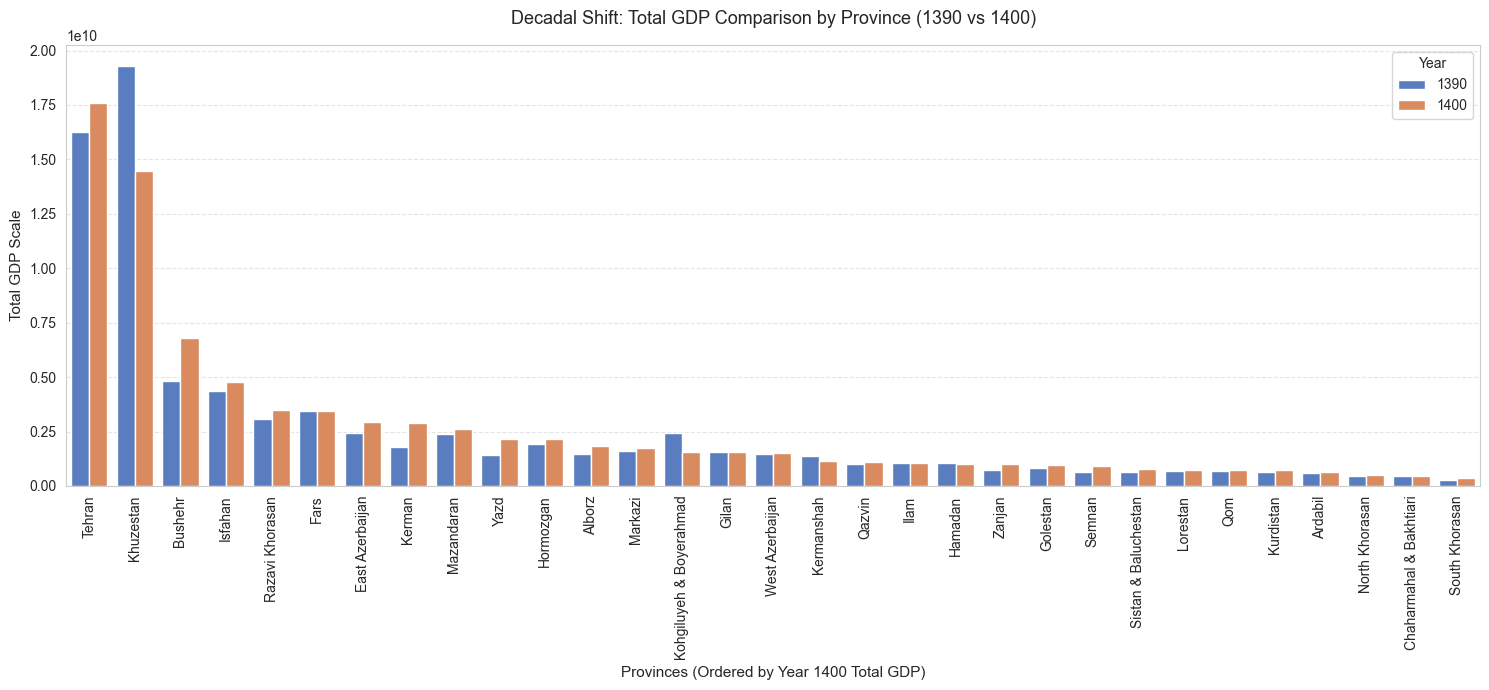

In [19]:
# 1. Filter data for the two benchmark years
df_compare = df_all_shares[df_all_shares['Year'].isin([1390, 1400])].copy()

# 2. Get sorting order based on Year 1400 (Highest to Lowest GDP)
order_gdp = df_compare[df_compare['Year'] == 1400].sort_values(by='GDP', ascending=False)['Province_EN'].tolist()

# 3. Plotting
plt.figure(figsize=(15, 7))
sns.barplot(
    data=df_compare,
    x='Province_EN', # Provinces moved to X-axis
    y='GDP',         # GDP moved to Y-axis
    hue='Year',
    order=order_gdp,
    palette='muted'
)

# Styling and X-axis label rotation
plt.title("Decadal Shift: Total GDP Comparison by Province (1390 vs 1400)", fontsize=13, pad=15)
plt.xlabel("Provinces (Ordered by Year 1400 Total GDP)", fontsize=11)
plt.ylabel("Total GDP Scale", fontsize=11)

# Rotate labels 90 degrees to prevent overlapping text on X-axis
plt.xticks(rotation=90, fontsize=10)
plt.grid(True, axis='y', linestyle='--', alpha=0.5)

plt.legend(title="Year", loc="upper right")
plt.tight_layout()
plt.show()

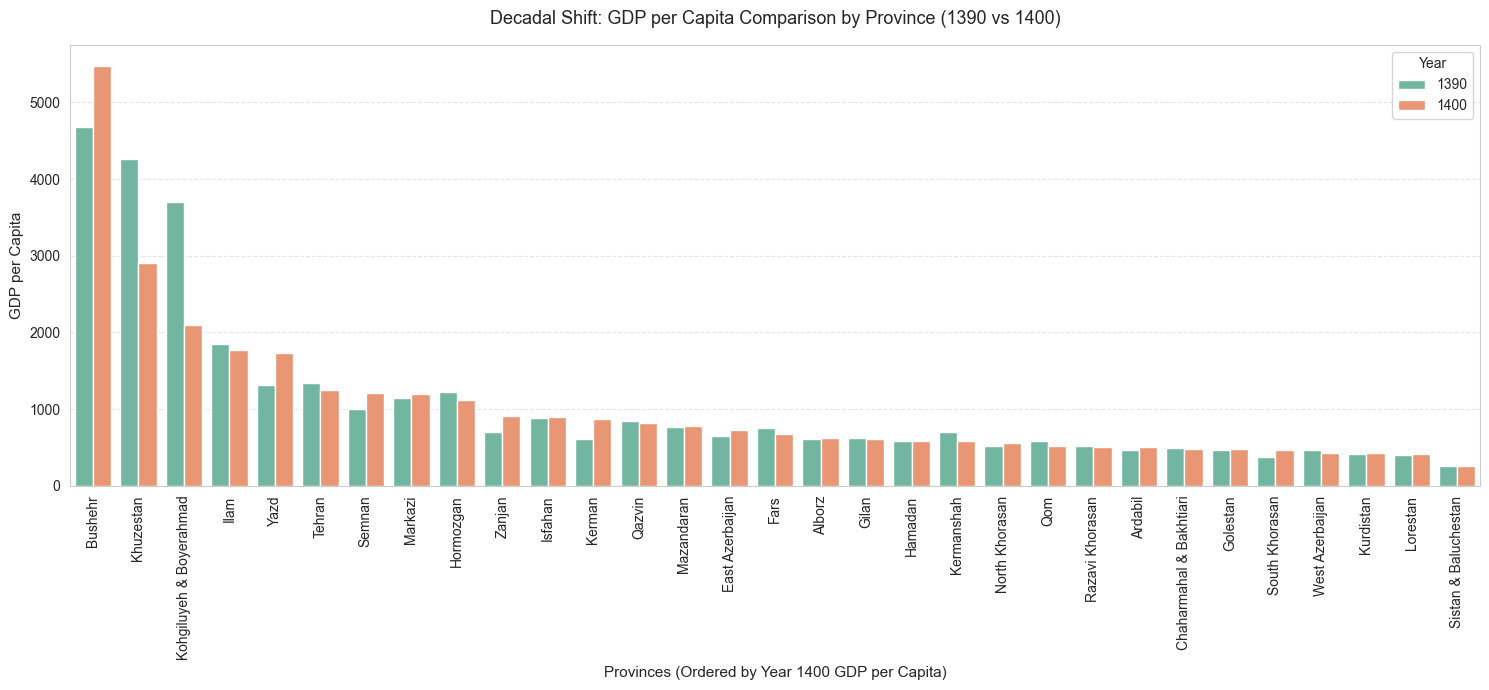

In [20]:
# 1. Get sorting order based on Year 1400 (Highest to Lowest GDP per Capita)
order_capita = df_compare[df_compare['Year'] == 1400].sort_values(by='GDP_per_Capita', ascending=False)['Province_EN'].tolist()

# 2. Plotting
plt.figure(figsize=(15, 7))
sns.barplot(
    data=df_compare,
    x='Province_EN', # Provinces moved to X-axis
    y='GDP_per_Capita', # GDP per Capita moved to Y-axis
    hue='Year',
    order=order_capita,
    palette='Set2'
)

# Styling and X-axis label rotation
plt.title("Decadal Shift: GDP per Capita Comparison by Province (1390 vs 1400)", fontsize=13, pad=15)
plt.xlabel("Provinces (Ordered by Year 1400 GDP per Capita)", fontsize=11)
plt.ylabel("GDP per Capita", fontsize=11)

# Rotate labels 90 degrees for clean display
plt.xticks(rotation=90, fontsize=10)
plt.grid(True, axis='y', linestyle='--', alpha=0.5)

plt.legend(title="Year", loc="upper right")
plt.tight_layout()
plt.show()

now I group the provinces by a proximate of its GDP share 

In [21]:
# Cell 1: Define structural group mapping for all 31 provinces
structural_groups = {
    # 1. Mega-Provinces (Main economic drivers)
    'تهران': '1_Mega_Provinces', 'خوزستان': '1_Mega_Provinces',
    
    # 2. Industrial & Service Hubs (High non-oil production)
    'اصفهان': '2_Industrial_Hubs', 'خراسان رضوی': '2_Industrial_Hubs', 
    'فارس': '2_Industrial_Hubs', 'آذربایجان شرقی': '2_Industrial_Hubs', 
    'کرمان': '2_Industrial_Hubs', 'مازندران': '2_Industrial_Hubs',
    
    # 3. Resource-Rich & Coastal (High gas flaring / maritime trade)
    'بوشهر': '3_Resource_Coastal', 'هرمزگان': '3_Resource_Coastal', 
    'کهگیلویه و بویراحمد': '3_Resource_Coastal', 'ایلام': '3_Resource_Coastal',
    
    # 4. Border & Peripheral (High potential for shadow economy)
    'سیستان و بلوچستان': '4_Border_Peripheral', 'کردستان': '4_Border_Peripheral', 
    'آذربایجان غربی': '4_Border_Peripheral', 'کرمانشاه': '4_Border_Peripheral', 
    'خراسان جنوبی': '4_Border_Peripheral', 'خراسان شمالی': '4_Border_Peripheral', 
    'اردبیل': '4_Border_Peripheral',
    
    # 5. Central & Mid-Tier (Balanced manufacturing and agriculture)
    'یزد': '5_Central_Mid_Tier', 'البرز': '5_Central_Mid_Tier', 
    'مرکزی': '5_Central_Mid_Tier', 'گیلان': '5_Central_Mid_Tier', 
    'قزوین': '5_Central_Mid_Tier', 'همدان': '5_Central_Mid_Tier', 
    'زنجان': '5_Central_Mid_Tier', 'سمنان': '5_Central_Mid_Tier',
    
    # 6. Small-Scale Economies (Provinces with shares under 1%)
    'گلستان': '6_Small_Scale', 'لرستان': '6_Small_Scale', 
    'قم': '6_Small_Scale', 'چهارمحال و بختیاری': '6_Small_Scale'
}

# Apply the group mapping to your dataframe
df_all_shares['Structural_Group'] = df_all_shares['نام استان'].map(structural_groups)

# Verify if any province missed the structural mapping
print("Mapping complete. Overview of records per structural group:")
print(df_all_shares.groupby('Structural_Group')['نام استان'].nunique())

Mapping complete. Overview of records per structural group:
Structural_Group
1_Mega_Provinces       2
2_Industrial_Hubs      6
3_Resource_Coastal     4
4_Border_Peripheral    7
5_Central_Mid_Tier     8
6_Small_Scale          4
Name: نام استان, dtype: int64


plot the GDP Share of each group 

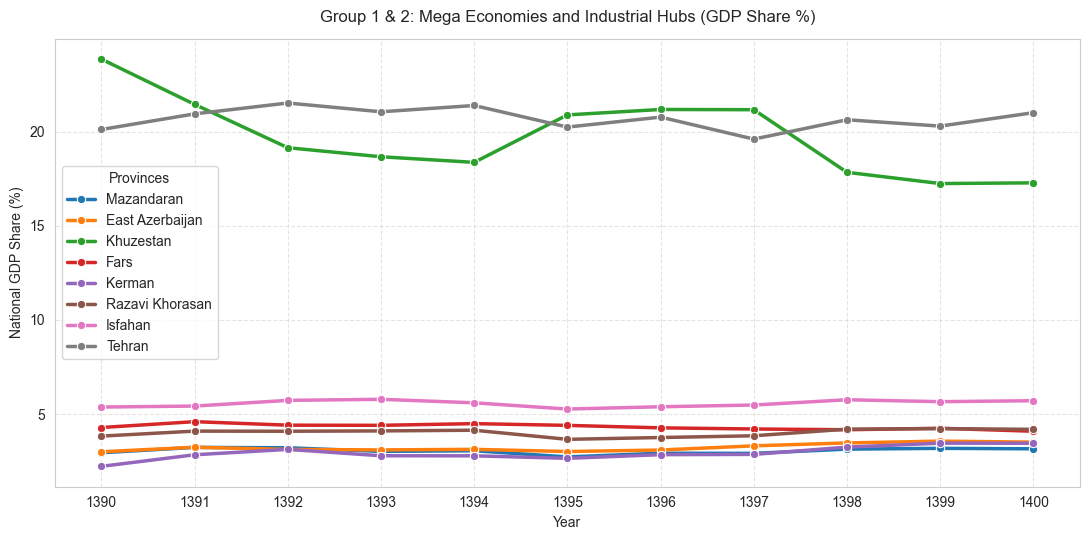

In [22]:
df_g1_g2 = df_all_shares[df_all_shares['Structural_Group'].isin(['1_Mega_Provinces', '2_Industrial_Hubs'])]

plt.figure(figsize=(11, 5.5))
# Using 'hue' with 'Province_EN' automatically creates a beautiful colored legend
sns.lineplot(
    data=df_g1_g2, 
    x='Year', 
    y='GDP_Share_Percent', 
    hue='Province_EN', 
    marker='o', 
    linewidth=2.5,
    palette='tab10' # Vibrant distinctive color palette
)

plt.title("Group 1 & 2: Mega Economies and Industrial Hubs (GDP Share %)", fontsize=12, pad=12)
plt.xlabel("Year")
plt.ylabel("National GDP Share (%)")
plt.xticks(df_g1_g2['Year'].unique())
plt.grid(True, linestyle='--', alpha=0.5)

# Place legend inside/best spot with colored labels
plt.legend(title="Provinces", loc="best", fontsize=10)
plt.tight_layout()
plt.show()

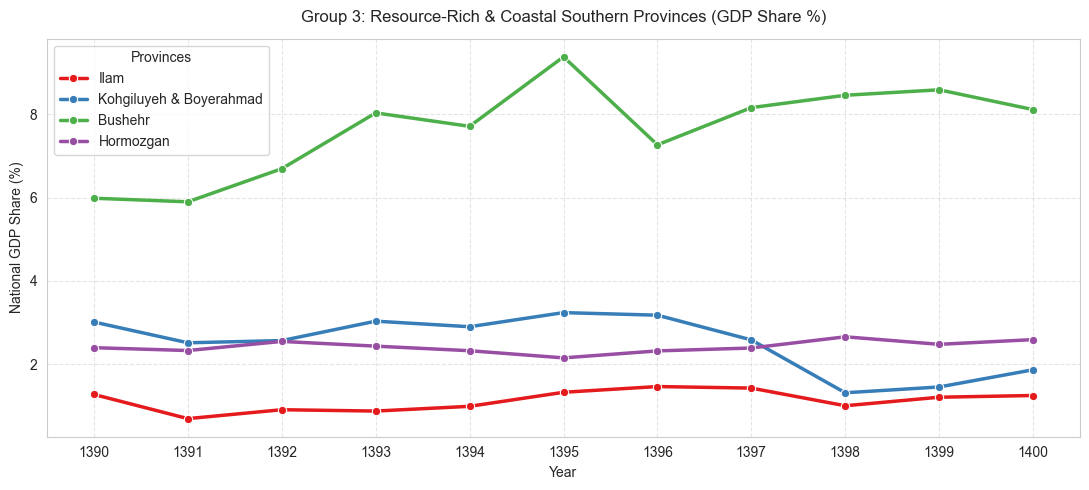

In [23]:
# Cell 3: Plot Group 3 with Colored Legend
df_g3 = df_all_shares[df_all_shares['Structural_Group'] == '3_Resource_Coastal']

plt.figure(figsize=(11, 5))
sns.lineplot(
    data=df_g3, 
    x='Year', 
    y='GDP_Share_Percent', 
    hue='Province_EN', 
    marker='o', 
    linewidth=2.5,
    palette='Set1'
)

plt.title("Group 3: Resource-Rich & Coastal Southern Provinces (GDP Share %)", fontsize=12, pad=12)
plt.xlabel("Year")
plt.ylabel("National GDP Share (%)")
plt.xticks(df_g3['Year'].unique())
plt.grid(True, linestyle='--', alpha=0.5)

plt.legend(title="Provinces", loc="best", fontsize=10)
plt.tight_layout()
plt.show()

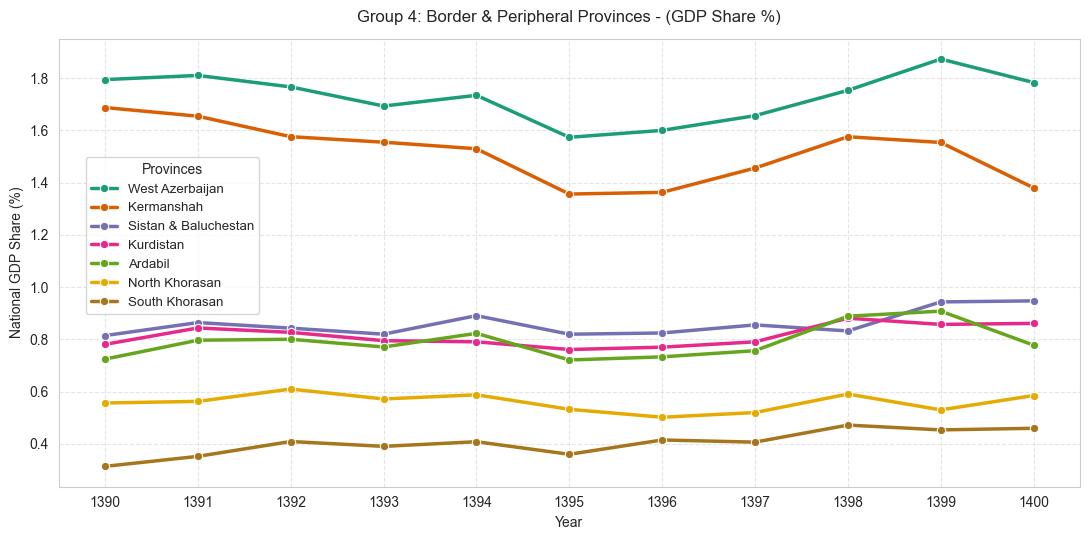

In [24]:
# Cell 4: Plot Group 4 with Colored Legend
df_g4 = df_all_shares[df_all_shares['Structural_Group'] == '4_Border_Peripheral']

plt.figure(figsize=(11, 5.5))
sns.lineplot(
    data=df_g4, 
    x='Year', 
    y='GDP_Share_Percent', 
    hue='Province_EN', 
    marker='o', 
    linewidth=2.5,
    palette='Dark2'
)

plt.title("Group 4: Border & Peripheral Provinces - (GDP Share %)", fontsize=12, pad=12)
plt.xlabel("Year")
plt.ylabel("National GDP Share (%)")
plt.xticks(df_g4['Year'].unique())
plt.grid(True, linestyle='--', alpha=0.5)

# Fix the legend INSIDE the plot area on the left side
# bbox_to_anchor=(X, Y) uses normalized coordinates from 0 to 1
# X=0.02 means 2% from the left edge
# Y=0.75 means 75% up from the bottom edge (places it nicely in the empty upper-left area)
plt.legend(title="Provinces", loc="upper left", bbox_to_anchor=(0.02, 0.75), fontsize=9.5)

plt.tight_layout()
plt.show()

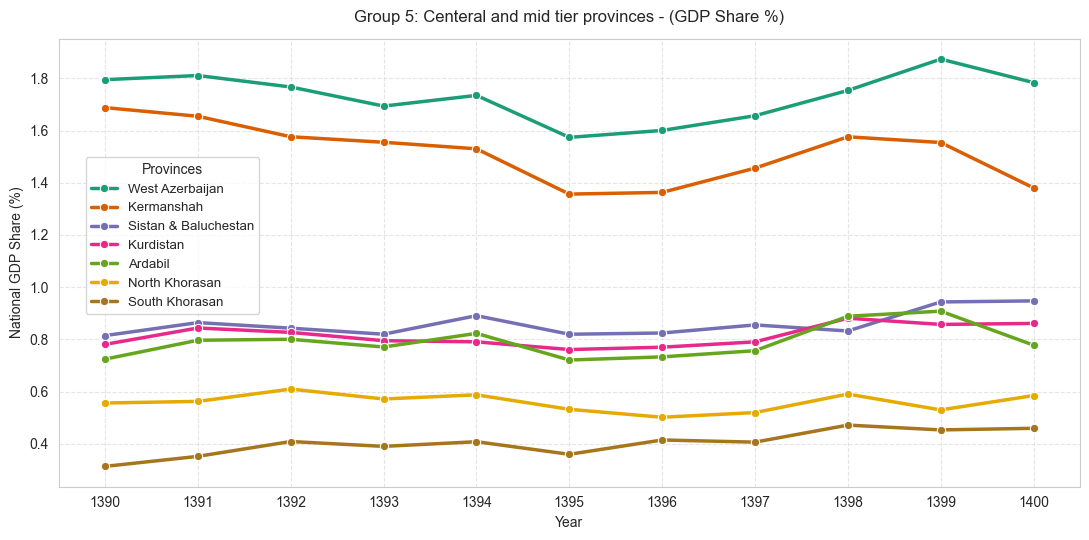

In [53]:
# Cell 4: Plot Group 4 with Colored Legend
df_g5 = df_all_shares[df_all_shares['Structural_Group'] == '5_Central_Mid_Tier']

plt.figure(figsize=(11, 5.5))
sns.lineplot(
    data=df_g4, 
    x='Year', 
    y='GDP_Share_Percent', 
    hue='Province_EN', 
    marker='o', 
    linewidth=2.5,
    palette='Dark2'
)

plt.title("Group 5: Centeral and mid tier provinces - (GDP Share %)", fontsize=12, pad=12)
plt.xlabel("Year")
plt.ylabel("National GDP Share (%)")
plt.xticks(df_g5['Year'].unique())
plt.grid(True, linestyle='--', alpha=0.5)

# Fix the legend INSIDE the plot area on the left side
# bbox_to_anchor=(X, Y) uses normalized coordinates from 0 to 1
# X=0.02 means 2% from the left edge
# Y=0.75 means 75% up from the bottom edge (places it nicely in the empty upper-left area)
plt.legend(title="Provinces", loc="upper left", bbox_to_anchor=(0.02, 0.75), fontsize=9.5)

plt.tight_layout()
plt.show()

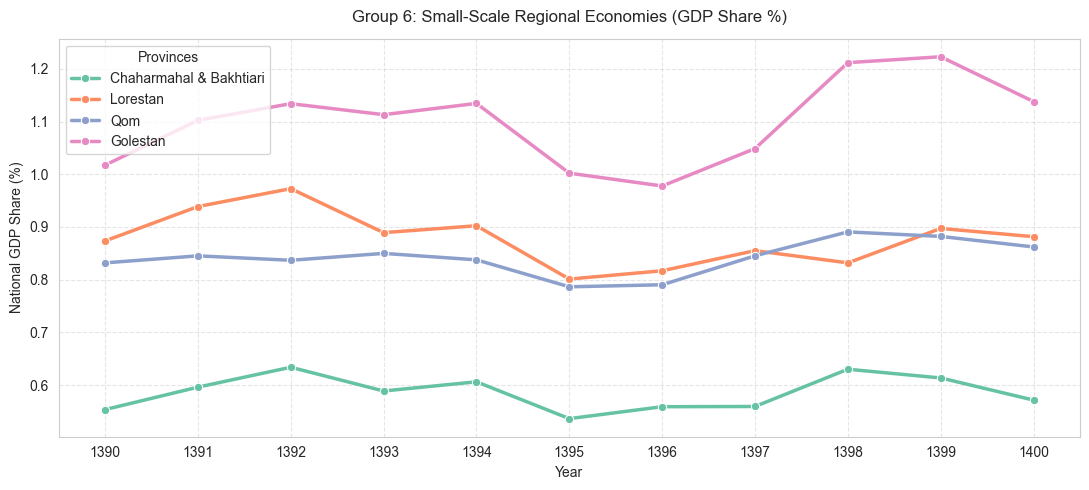

In [25]:
# Cell 6: Plot Group 6 with Colored Legend
df_g6 = df_all_shares[df_all_shares['Structural_Group'] == '6_Small_Scale']

plt.figure(figsize=(11, 5))
sns.lineplot(
    data=df_g6, 
    x='Year', 
    y='GDP_Share_Percent', 
    hue='Province_EN', 
    marker='o', 
    linewidth=2.5,
    palette='Set2'
)

plt.title("Group 6: Small-Scale Regional Economies (GDP Share %)", fontsize=12, pad=12)
plt.xlabel("Year")
plt.ylabel("National GDP Share (%)")
plt.xticks(df_g6['Year'].unique())
plt.grid(True, linestyle='--', alpha=0.5)

plt.legend(title="Provinces", loc="best", fontsize=10)
plt.tight_layout()
plt.show()

# Trends of NTL for each province

In [12]:
ntl_province_annual = pd.read_csv(str(ROOT / "data/Iran_Province_NTL_Annual/Iran_Annual_NTLperCapita_Master_2012_2024.csv"))

In this part I rank the NTL of province and compare the 1392 with 1400

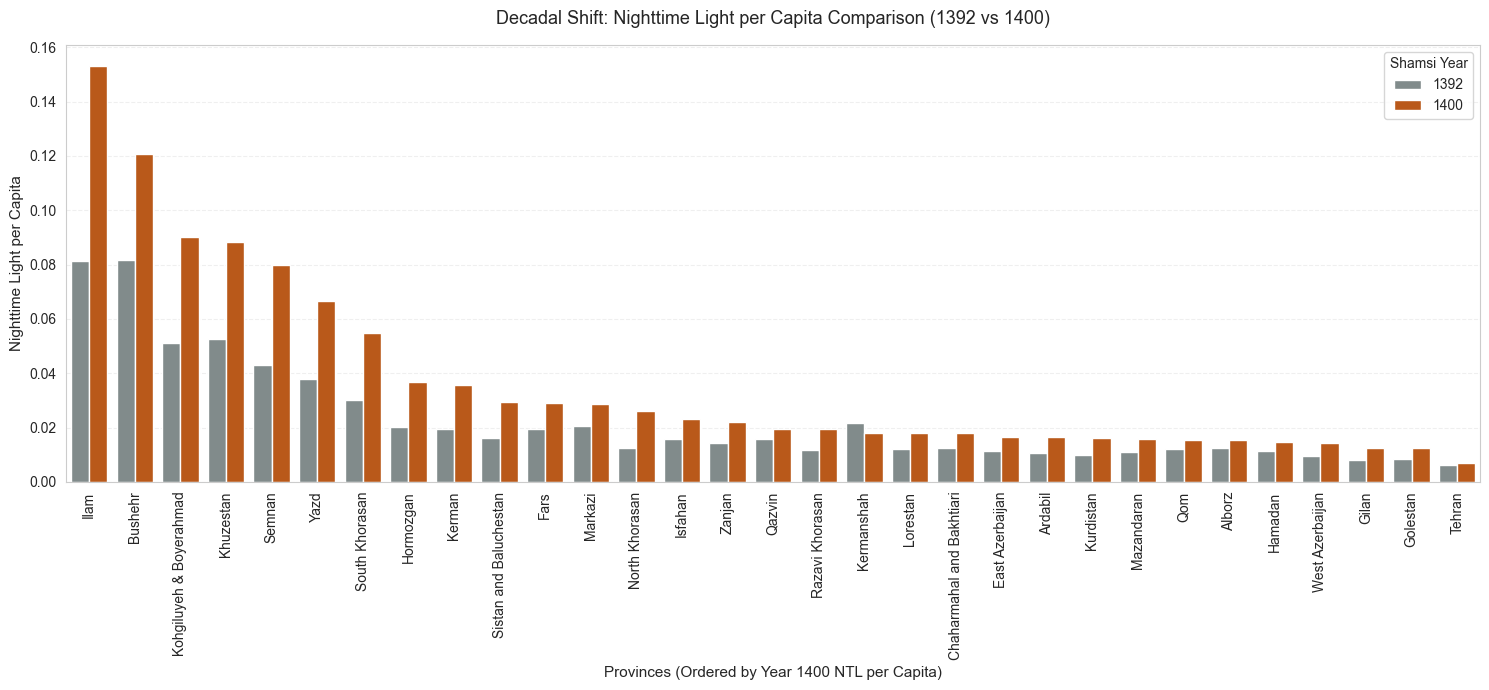

In [14]:
# Cell: Compare NTL per Capita (NTL_Per_Capita) between 1392 and 1400 with high contrast

# Ensure the benchmark data is freshly filtered
df_comp_years = ntl_province_annual[ntl_province_annual['Year_Shamsi_NTL'].isin([1392, 1400])].copy()

# Sort provinces based on the Year 1400 NTL per Capita for clean ordering
order_capita = df_comp_years[df_comp_years['Year_Shamsi_NTL'] == 1400].sort_values(by='NTL_Per_Capita', ascending=False)['Area'].tolist()

# Define a custom high-contrast academic palette
# 1392: Muted Slate Gray (Background baseline)
# 1400: Vivid Amber Orange (Target highlight)
custom_colors = {1392: '#7f8c8d', 1400: '#d35400'}

plt.figure(figsize=(15, 7))
sns.barplot(
    data=df_comp_years,
    x='Area',
    y='NTL_Per_Capita',
    hue='Year_Shamsi_NTL',
    order=order_capita,
    palette=custom_colors
)

# Layout adjustments and configurations
plt.title("Decadal Shift: Nighttime Light per Capita Comparison (1392 vs 1400)", fontsize=13, pad=15)
plt.xlabel("Provinces (Ordered by Year 1400 NTL per Capita)", fontsize=11)
plt.ylabel("Nighttime Light per Capita", fontsize=11)

plt.xticks(rotation=90, fontsize=10)
plt.grid(True, axis='y', linestyle='--', alpha=0.3)
plt.legend(title="Shamsi Year")

plt.tight_layout()
plt.show()

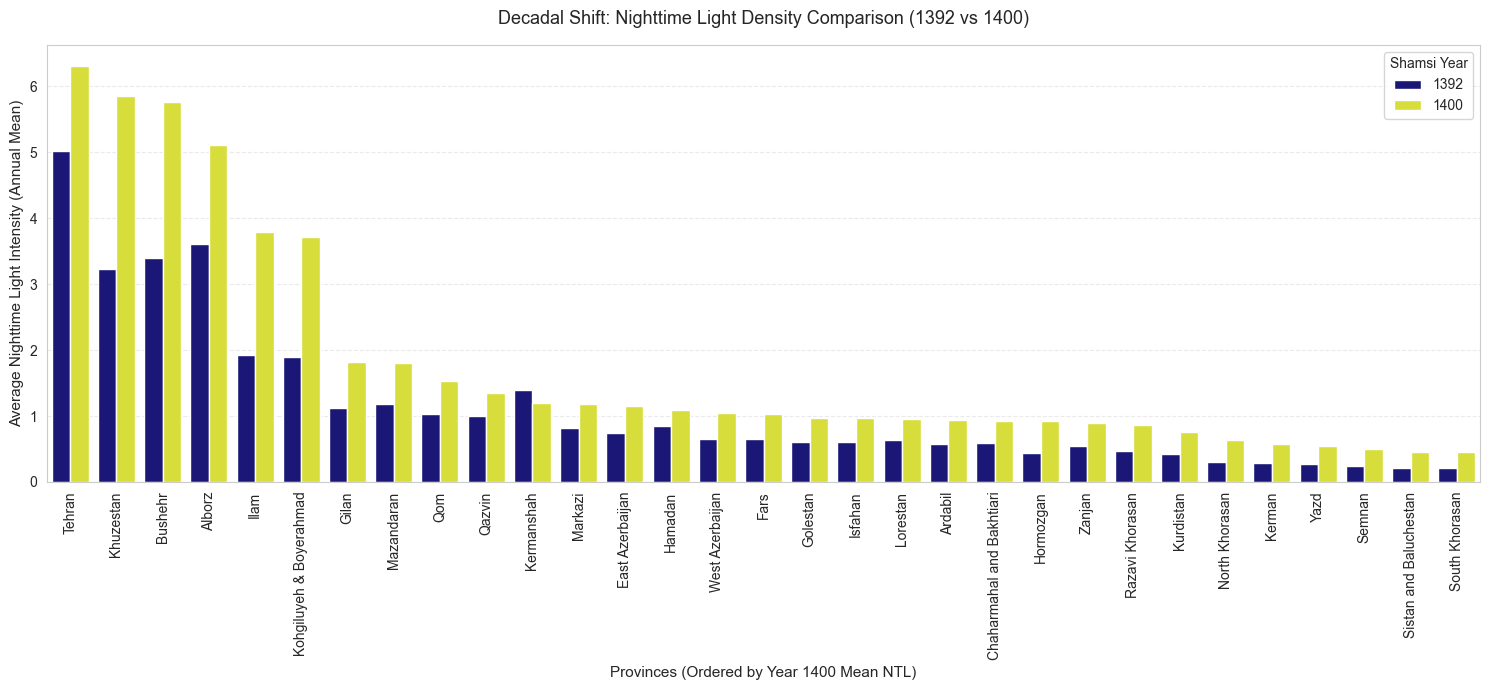

In [28]:
# Cell: Compare NTL Density (Annual_Mean) between 2013 (1392) and 1400

# Sort provinces based on the Year 1400 Mean NTL to see the density ranking
order_mean = df_comp_years[df_comp_years['Year_Shamsi_NTL'] == 1400].sort_values(by='Annual_Mean', ascending=False)['Area'].tolist()

plt.figure(figsize=(15, 7))
sns.barplot(
    data=df_comp_years,
    x='Area',
    y='Annual_Mean',
    hue='Year_Shamsi_NTL',
    order=order_mean,
    palette='plasma'
)

plt.title("Decadal Shift: Nighttime Light Density Comparison (1392 vs 1400)", fontsize=13, pad=15)
plt.xlabel("Provinces (Ordered by Year 1400 Mean NTL)", fontsize=11)
plt.ylabel("Average Nighttime Light Intensity (Annual Mean)", fontsize=11)
plt.xticks(rotation=90, fontsize=10)
plt.grid(True, axis='y', linestyle='--', alpha=0.4)
plt.legend(title="Shamsi Year")

plt.tight_layout()
plt.show()

# Final Cleaning for the Regression in the Stata

Quartely GDP and Quarterly NTL for IRAN

In [29]:
df.to_csv(
    str(ROOT / "data/Validation/national_ntl_gdp_validation_clean.csv"),
    index=False
)
# Export provincial validation data directly to Stata format

df.to_stata(
    str(ROOT / "data/Validation/national_ntl_gdp_validation_clean.dta"),
    write_index=False,
    version=118
)


GDP and NTL for Province
in this part we have a lot of cleaning detail which is not important at the end i make the final dta for regression in the stata

In [15]:
# Step 12: Prepare provincial GDP data for export and regression

gdp_prov_clean = gdp_province.copy()

# Rename Persian province column to a cleaner English name
gdp_prov_clean = gdp_prov_clean.rename(columns={
    'نام استان': 'Province_FA'
})

# Add English province names
gdp_prov_clean['Province_EN'] = gdp_prov_clean['Province_FA'].map(all_provinces_translation)

# Keep main variables
gdp_prov_sel = gdp_prov_clean[
    [
        'Year',
        'Province_FA',
        'Province_EN',
        'GDP',
        'GDP_per_Capita'
    ]
].copy()

gdp_prov_sel.head()

,Year,Province_FA,Province_EN,GDP,GDP_per_Capita
0,1390,مرکزی,Markazi,1.625908e+09,1149.897504
1,1390,گیلان,Gilan,1.566321e+09,631.358712
2,1390,مازندران,Mazandaran,2.378234e+09,773.675423
3,1390,آذربایجان شرقی,East Azerbaijan,2.418387e+09,649.297627
4,1390,آذربایجان غربی,West Azerbaijan,1.451110e+09,471.051513


In [16]:
# Step 13: Prepare provincial annual NTL data - fixed version

ntl_prov_clean = ntl_province_annual.copy()

# Keep only needed columns BEFORE renaming to avoid duplicate Year columns
ntl_prov_sel = ntl_prov_clean[
    [
        'Year_Shamsi_NTL',
        'Area',
        'NTL_Per_Capita',
        'Annual_Mean'
    ]
].copy()

# Rename columns for consistency
ntl_prov_sel = ntl_prov_sel.rename(columns={
    'Year_Shamsi_NTL': 'Year',
    'Area': 'Province_EN'
})
# Final harmonization of province names

gdp_prov_sel['Province_EN'] = gdp_prov_sel['Province_EN'].replace({
    'Sistan & Baluchestan': 'Sistan and Baluchestan',
    'Chaharmahal & Bakhtiari': 'Chaharmahal and Bakhtiari'
})
# Make sure Year is numeric
ntl_prov_sel['Year'] = pd.to_numeric(ntl_prov_sel['Year'], errors='coerce')

ntl_prov_sel.head()

,Year,Province_EN,NTL_Per_Capita,Annual_Mean
0,1391,Yazd,0.034136,0.242350
1,1391,Sistan and Baluchestan,0.015385,0.196490
2,1391,Kerman,0.018239,0.262493
3,1391,Hormozgan,0.018594,0.390567
4,1391,Fars,0.017104,0.564258


In [32]:
print(sorted(ntl_prov_sel['Province_EN'].dropna().unique()))

['Alborz', 'Ardabil', 'Bushehr', 'Chaharmahal and Bakhtiari', 'East Azerbaijan', 'Fars', 'Gilan', 'Golestan', 'Hamadan', 'Hormozgan', 'Ilam', 'Isfahan', 'Kerman', 'Kermanshah', 'Khuzestan', 'Kohgiluyeh & Boyerahmad', 'Kurdistan', 'Lorestan', 'Markazi', 'Mazandaran', 'North Khorasan', 'Qazvin', 'Qom', 'Razavi Khorasan', 'Semnan', 'Sistan and Baluchestan', 'South Khorasan', 'Tehran', 'West Azerbaijan', 'Yazd', 'Zanjan']


In [17]:
# Step 14: Merge provincial GDP and NTL data

df_province_validation = pd.merge(
    gdp_prov_sel,
    ntl_prov_sel,
    on=['Year', 'Province_EN'],
    how='inner'
)

print(df_province_validation.shape)
df_province_validation.head()

(310, 7)


,Year,Province_FA,Province_EN,GDP,GDP_per_Capita,NTL_Per_Capita,Annual_Mean
0,1391,مرکزی,Markazi,1.541987e+09,1089.456045,0.017361,0.693191
1,1391,گیلان,Gilan,1.509628e+09,606.082136,0.007535,1.061691
2,1391,مازندران,Mazandaran,2.385602e+09,768.008449,0.010322,1.086778
3,1391,آذربایجان شرقی,East Azerbaijan,2.392357e+09,636.138508,0.009544,0.620136
4,1391,آذربایجان غربی,West Azerbaijan,1.339611e+09,428.304073,0.008590,0.570192


In [18]:
# Step 15: Check unmatched provinces

gdp_provinces = set(gdp_prov_sel['Province_EN'].dropna().unique())
ntl_provinces = set(ntl_prov_sel['Province_EN'].dropna().unique())

print("In GDP but not in NTL:")
print(gdp_provinces - ntl_provinces)

print("\nIn NTL but not in GDP:")
print(ntl_provinces - gdp_provinces)

In GDP but not in NTL:
set()

In NTL but not in GDP:
set()


In [19]:
# Step 16: Create log variables for provincial validation

for col in ['GDP', 'GDP_per_Capita', 'NTL_Per_Capita', 'Annual_Mean']:
    df_province_validation[f'log_{col}'] = np.log(df_province_validation[col])

df_province_validation.head()

,Year,Province_FA,Province_EN,GDP,GDP_per_Capita,NTL_Per_Capita,Annual_Mean,log_GDP,log_GDP_per_Capita,log_NTL_Per_Capita,log_Annual_Mean
0,1391,مرکزی,Markazi,1.541987e+09,1089.456045,0.017361,0.693191,21.156337,6.993434,-4.053541,-0.366450
1,1391,گیلان,Gilan,1.509628e+09,606.082136,0.007535,1.061691,21.135129,6.407016,-4.888152,0.059863
2,1391,مازندران,Mazandaran,2.385602e+09,768.008449,0.010322,1.086778,21.592718,6.643801,-4.573436,0.083217
3,1391,آذربایجان شرقی,East Azerbaijan,2.392357e+09,636.138508,0.009544,0.620136,21.595545,6.455416,-4.651864,-0.477816
4,1391,آذربایجان غربی,West Azerbaijan,1.339611e+09,428.304073,0.008590,0.570192,21.015645,6.059833,-4.757162,-0.561782


In [36]:
# Step 17: Export provincial validation dataset for Stata

import os

out_dir = str(ROOT / "data/Validation")
os.makedirs(out_dir, exist_ok=True)

df_province_validation.to_csv(
    os.path.join(out_dir, "province_ntl_gdp_validation_clean.csv"),
    index=False,
    encoding='utf-8-sig'
)
# Export provincial validation data directly to Stata format

df_province_validation.to_stata(
    str(ROOT / "data/Validation/province_ntl_gdp_validation_clean.dta"),
    write_index=False,
    version=118
)

print("Stata file exported successfully.")

print("Provincial validation dataset exported successfully.")
print(out_dir)

Stata file exported successfully.
Provincial validation dataset exported successfully.
Data\Validation


# Graph of Regression Validation

Province GDP on NTL yearly

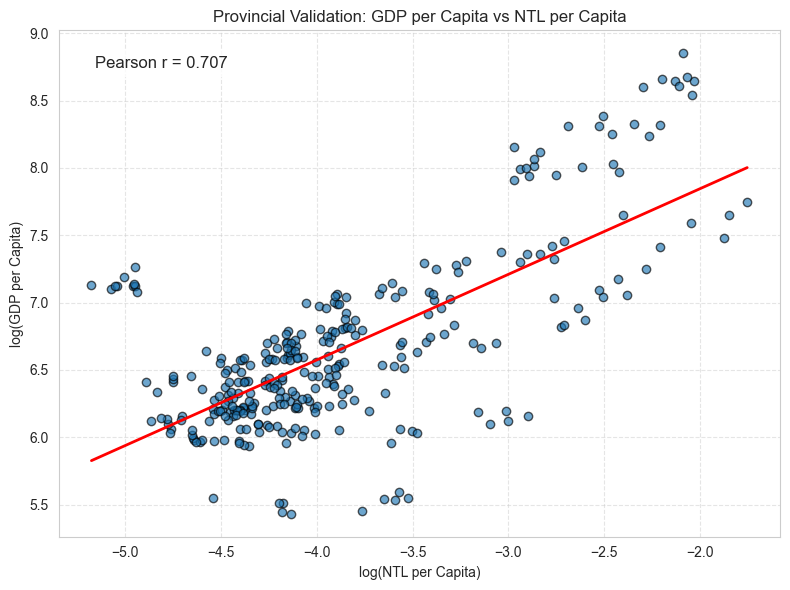

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# Calculate Pearson correlation
r, p_value = pearsonr(
    df_province_validation['log_NTL_Per_Capita'],
    df_province_validation['log_GDP_per_Capita']
)

# Fit regression line
beta, intercept = np.polyfit(
    df_province_validation['log_NTL_Per_Capita'],
    df_province_validation['log_GDP_per_Capita'],
    1
)

# Create figure
plt.figure(figsize=(8, 6))

# Scatter
plt.scatter(
    df_province_validation['log_NTL_Per_Capita'],
    df_province_validation['log_GDP_per_Capita'],
    alpha=0.65,
    edgecolors='k'
)

# Regression line
x = np.linspace(
    df_province_validation['log_NTL_Per_Capita'].min(),
    df_province_validation['log_NTL_Per_Capita'].max(),
    100
)

plt.plot(
    x,
    intercept + beta * x,
    color='red',
    linewidth=2
)

# Display Pearson coefficient
plt.text(
    0.05,
    0.95,
    f'Pearson r = {r:.3f}',
    transform=plt.gca().transAxes,
    fontsize=12,
    verticalalignment='top',
    bbox=dict(facecolor='white', alpha=0.8)
)

plt.title('Provincial Validation: GDP per Capita vs NTL per Capita')
plt.xlabel('log(NTL per Capita)')
plt.ylabel('log(GDP per Capita)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

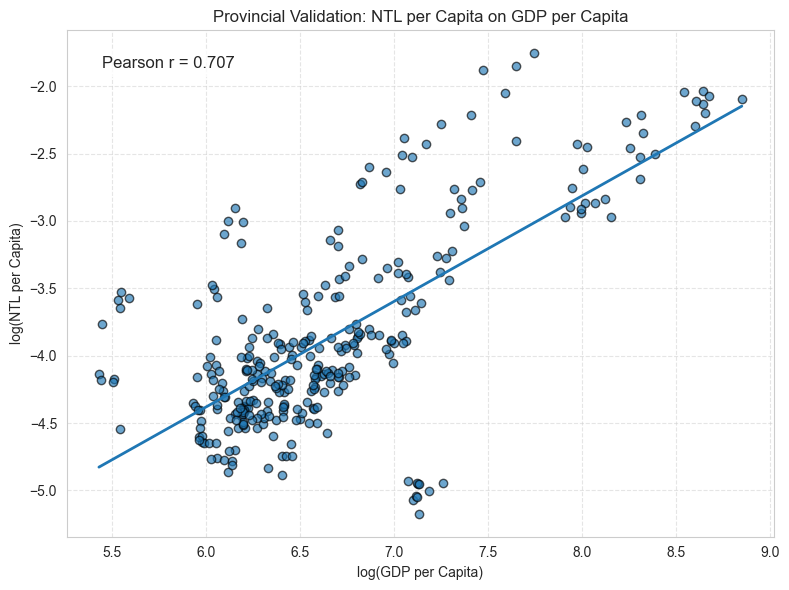

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# X = GDP per capita
x = df_province_validation['log_GDP_per_Capita']

# Y = NTL per capita
y = df_province_validation['log_NTL_Per_Capita']

# Pearson correlation
r, p_value = pearsonr(x, y)

# Regression: NTL on GDP
beta, intercept = np.polyfit(x, y, 1)

# Create figure
plt.figure(figsize=(8, 6))

# Scatter
plt.scatter(
    x,
    y,
    alpha=0.65,
    edgecolors='k'
)

# Regression line
x_line = np.linspace(
    x.min(),
    x.max(),
    100
)

plt.plot(
    x_line,
    intercept + beta * x_line,
    linewidth=2
)

# Pearson coefficient
plt.text(
    0.05,
    0.95,
    f'Pearson r = {r:.3f}',
    transform=plt.gca().transAxes,
    fontsize=12,
    verticalalignment='top',
    bbox=dict(facecolor='white', alpha=0.8)
)

plt.title('Provincial Validation: NTL per Capita on GDP per Capita')
plt.xlabel('log(GDP per Capita)')
plt.ylabel('log(NTL per Capita)')

plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Spearman Rank Correlation

In this part I will check the Rank of the provinces in the NTL and GDP and see if there is any relation in the two ranking

In [38]:
spearman_corr, spearman_p = spearmanr(
    df_province_validation['GDP_per_Capita'],
    df_province_validation['NTL_Per_Capita']
)

print("Spearman Rank Correlation: GDP per Capita vs NTL per Capita")
print("-----------------------------------------------------------")
print(f"Spearman rho: {spearman_corr:.3f}")
print(f"P-value: {spearman_p:.4f}")

Spearman Rank Correlation: GDP per Capita vs NTL per Capita
-----------------------------------------------------------
Spearman rho: 0.573
P-value: 0.0000


In [39]:
# Step 19: Spearman rank correlation by year

spearman_by_year = []

for year, group in df_province_validation.groupby('Year'):
    rho, pval = spearmanr(
        group['GDP_per_Capita'],
        group['NTL_Per_Capita']
    )
    
    spearman_by_year.append({
        'Year': year,
        'Spearman_rho': rho,
        'P_value': pval,
        'N_provinces': group['Province_EN'].nunique()
    })

spearman_by_year = pd.DataFrame(spearman_by_year)

spearman_by_year

,Year,Spearman_rho,P_value,N_provinces
0,1391,0.531048,0.002114,31
1,1392,0.570161,0.000812,31
2,1393,0.605242,0.000309,31
3,1394,0.611290,0.000259,31
4,1395,0.670565,0.000037,31
5,1396,0.550806,0.001323,31
6,1397,0.562903,0.000979,31
7,1398,0.568548,0.000847,31
8,1399,0.517742,0.002853,31
9,1400,0.537097,0.001837,31


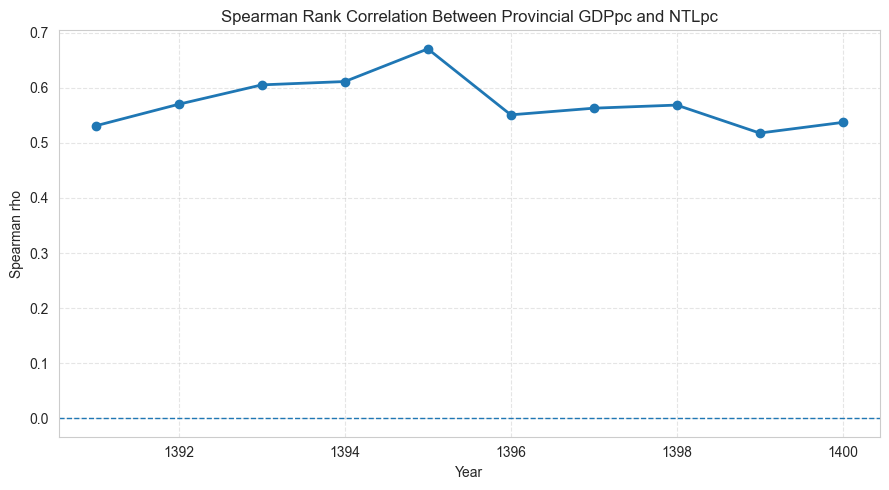

In [40]:
# Step 20: Plot Spearman correlation over time

plt.figure(figsize=(9, 5))

plt.plot(
    spearman_by_year['Year'],
    spearman_by_year['Spearman_rho'],
    marker='o',
    linewidth=2
)

plt.axhline(0, linestyle='--', linewidth=1)

plt.title('Spearman Rank Correlation Between Provincial GDPpc and NTLpc')
plt.xlabel('Year')
plt.ylabel('Spearman rho')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [41]:
# Step 21: Province ranking comparison for benchmark year

benchmark_year = 1400

rank_df = df_province_validation[df_province_validation['Year'] == benchmark_year].copy()

rank_df['GDPpc_rank'] = rank_df['GDP_per_Capita'].rank(ascending=False, method='min')
rank_df['NTLpc_rank'] = rank_df['NTL_Per_Capita'].rank(ascending=False, method='min')
rank_df['Rank_Difference'] = rank_df['GDPpc_rank'] - rank_df['NTLpc_rank']

rank_df = rank_df[
    [
        'Province_EN',
        'GDP_per_Capita',
        'NTL_Per_Capita',
        'GDPpc_rank',
        'NTLpc_rank',
        'Rank_Difference'
    ]
].sort_values('GDPpc_rank')

rank_df

,Province_EN,GDP_per_Capita,NTL_Per_Capita,GDPpc_rank,NTLpc_rank,Rank_Difference
297,Bushehr,5474.674410,0.120884,1.0,2.0,-1.0
285,Khuzestan,2900.187158,0.088387,2.0,4.0,-2.0
296,Kohgiluyeh & Boyerahmad,2102.109882,0.090325,3.0,3.0,0.0
295,Ilam,1765.973483,0.153228,4.0,1.0,3.0
300,Yazd,1734.754513,0.066554,5.0,6.0,-1.0
302,Tehran,1254.736318,0.007087,6.0,31.0,-25.0
299,Semnan,1208.424210,0.079816,7.0,5.0,2.0
279,Markazi,1196.941961,0.028601,8.0,12.0,-4.0
301,Hormozgan,1122.989857,0.036711,9.0,8.0,1.0
298,Zanjan,905.339970,0.021919,10.0,15.0,-5.0


In [42]:
# Step 22: Export rank validation outputs

import os

out_dir = str(ROOT / "output/Validation")
os.makedirs(out_dir, exist_ok=True)

spearman_by_year.to_excel(
    os.path.join(out_dir, "spearman_rank_validation_by_year.xlsx"),
    index=False
)

rank_df.to_excel(
    os.path.join(out_dir, f"province_rank_comparison_{benchmark_year}.xlsx"),
    index=False
)

print("Rank validation outputs saved successfully.")

Rank validation outputs saved successfully.


# HIES summary Data 

in this part with recommandation of my Prof i use HIES for validation 
i use the HBSIR library for the summary data and then use the expenditure for validation with both GDP and NTL

first I make the data for Expenditure per capita(weighted)

In [43]:
# ============================================================
# Section: HIES — Weighted Expenditure per Capita (Provincial + National)
# ============================================================

import hbsir

years = list(range(1390, 1404))
results_provincial = []
results_national = []

for year in years:
    try:
        # Load expenditure and add province
        table = hbsir.load_table("Expenditures", years=[year])
        table = hbsir.add_attribute(table, name="Province")

        # Sum to household level
        hh_exp = (
            table
            .groupby(["Province", "ID"])["Net_Expenditure"]
            .sum()
            .reset_index(name="HH_Total_Expenditure")
        )
        del table

        # Load household size and weight
        members = hbsir.load_table("Number_of_Members", years=[year])
        weights = hbsir.load_table("Weight", years=[year])

        # Merge and calculate per capita
        hh = pd.merge(hh_exp, members[["ID", "Members"]], on="ID", how="left")
        hh = pd.merge(hh, weights[["ID", "Weight"]], on="ID", how="left")
        del members, weights, hh_exp

        hh["exp_per_capita"] = hh["HH_Total_Expenditure"] / hh["Members"]

        # Provincial weighted average
        agg_prov = (
            hh
            .groupby("Province")
            .apply(lambda x: np.average(x["exp_per_capita"], weights=x["Weight"]), include_groups=False)
            .reset_index(name="avg_exp_per_capita")
        )
        agg_prov["Year"] = year
        results_provincial.append(agg_prov)

        # National weighted average — directly from household level
        national_avg = np.average(hh["exp_per_capita"], weights=hh["Weight"])
        results_national.append({
            "Province": "National",
            "avg_exp_per_capita": national_avg,
            "Year": year
        })

        del hh
        print(f"Year {year} done")

    except Exception as e:
        print(f"Year {year} failed: {type(e).__name__}: {e}")

# Combine provincial and national into one dataframe
exp_provincial = pd.concat(results_provincial, ignore_index=True)
exp_national = pd.DataFrame(results_national)
exp_full = pd.concat([exp_provincial, exp_national], ignore_index=True)

# Fix province names — replace underscores with spaces
exp_full['Province'] = (
    exp_full['Province']
    .str.replace('_', ' ')
    .replace({'Kohgiluyeh and Boyer Ahmad': 'Kohgiluyeh & Boyerahmad'})
)

print(f"Shape: {exp_full.shape}")
print(exp_full[exp_full['Province'] == 'National'])

AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Year 1390 done
Year 1391 done
Year 1392 done
Year 1393 done
Year 1394 done
Year 1395 done
Year 1396 done
Year 1397 done
Year 1398 done
Year 1399 done
Year 1400 done
Year 1401 done
Year 1402 done
Year 1403 done
Shape: (448, 3)
     Province  avg_exp_per_capita  Year
434  National        3.640868e+07  1390
435  National        4.642346e+07  1391
436  National        5.914504e+07  1392
437  National        6.744903e+07  1393
438  National        7.501525e+07  1394
439  National        8.205130e+07  1395
440  National        9.587167e+07  1396
441  National        1.175556e+08  1397
442  National        1.451349e+08  1398
443  National        1.914664e+08  1399
444  National        2.885386e+08  1400
445  National        4.398214e+08  1401
446  National        6.774763e+08  1402
447  National        8.967338e+08  1403


In [44]:
cpi_provincial = pd.read_excel(
    str(ROOT / "data/CPI/ts_national_140502-14050313161356.xlsx"),
    sheet_name='جدول 7',
    header=None
)
cpi_provincial.head()

,0,1,2,3,4,5,6,7,8,9,...,184,185,186,187,188,189,190,191,192,193
0,سری زمانی شاخص قیمت مصرف کننده کل خانوارها به ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,کد استان,نام استان,سال 1390,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,فروردین,اردیبهشت,خرداد,تیر,مرداد,شهریور,مهر,آبان,...,خرداد,تیر,مرداد,شهریور,مهر,آبان,آذر,دی,بهمن,اسفند
3,99,كل كشور,10.855119,11.154133,11.353604,11.563497,11.823574,12.015879,12.216896,12.353747,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,00,مركزئ,10.721553,10.881314,11.049163,11.330267,11.524149,11.632053,11.762057,11.917889,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [45]:
# Extract annual provincial CPI from monthly data
provinces = cpi_provincial.iloc[3:, 1].values
data = cpi_provincial.iloc[3:, 2:].values.astype(float)
years_cpi = list(range(1390, 1390 + data.shape[1] // 12))

records = []
for p_idx, province in enumerate(provinces):
    for y_idx, year in enumerate(years_cpi):
        monthly = data[p_idx, y_idx*12:(y_idx+1)*12]
        records.append({
            'Province_FA': province,
            'Year': year,
            'CPI': np.nanmean(monthly)
        })

cpi_provincial = pd.DataFrame(records)

# Map Persian names to English
fa_to_en = {
    'كل كشور': 'National', 'مركزئ': 'Markazi', 'گيلان': 'Gilan',
    'مازندران': 'Mazandaran', 'آذربايجان شرقي': 'East Azerbaijan',
    'آذربايجان غربي': 'West Azerbaijan', 'كرمانشاه': 'Kermanshah',
    'خوزستان': 'Khuzestan', 'فارس': 'Fars', 'كرمان': 'Kerman',
    'خراسان رضوئ': 'Razavi Khorasan', 'اصفهان': 'Isfahan',
    'سيستان وبلوچستان': 'Sistan and Baluchestan', 'كردستان': 'Kurdistan',
    'همدان': 'Hamadan', 'چهارمحال وبختيارئ': 'Chaharmahal and Bakhtiari',
    'لرستان': 'Lorestan', 'ايلام': 'Ilam',
    'كهگيلويه وبويراحمد': 'Kohgiluyeh & Boyerahmad', 'بوشهر': 'Bushehr',
    'زنجان': 'Zanjan', 'سمنان': 'Semnan', 'يزد': 'Yazd',
    'هرمزگان': 'Hormozgan', 'تهران': 'Tehran', 'اردبيل': 'Ardabil',
    'قم': 'Qom', 'قزوين': 'Qazvin', 'گلستان': 'Golestan',
    'خراسان شمالي': 'North Khorasan', 'خراسان جنوبي': 'South Khorasan',
    'البرز': 'Alborz',
}

cpi_provincial['Province_EN'] = cpi_provincial['Province_FA'].map(fa_to_en)

# Keep only 1390-1403 and clean up
cpi_provincial = cpi_provincial[cpi_provincial['Year'].between(1390, 1403)]
cpi_provincial = cpi_provincial[['Province_EN', 'Year', 'CPI']].reset_index(drop=True)

print(cpi_provincial.shape)
print(cpi_provincial[cpi_provincial['Province_EN'] == 'Tehran'])

(448, 3)
    Province_EN  Year         CPI
336      Tehran  1390   12.685585
337      Tehran  1391   15.986192
338      Tehran  1392   20.662361
339      Tehran  1393   23.871317
340      Tehran  1394   26.881994
341      Tehran  1395   28.147901
342      Tehran  1396   30.433574
343      Tehran  1397   39.201116
344      Tehran  1398   53.161242
345      Tehran  1399   72.682115
346      Tehran  1400  100.000000
347      Tehran  1401  142.518868
348      Tehran  1402  194.500133
349      Tehran  1403  257.721379


In [46]:
# Merge CPI into exp_full
exp_full = pd.merge(
    exp_full,
    cpi_provincial,
    left_on=['Province', 'Year'],
    right_on=['Province_EN', 'Year'],
    how='left'
)

exp_full['real_exp_per_capita'] = exp_full['avg_exp_per_capita'] / exp_full['CPI'] * 100
exp_full = exp_full.drop(columns=['Province_EN'])

# Sanity check
print(exp_full[exp_full['Province'] == 'National'][
    ['Year', 'avg_exp_per_capita', 'CPI', 'real_exp_per_capita']
])

     Year  avg_exp_per_capita         CPI  real_exp_per_capita
434  1390        3.640868e+07   12.072760         3.015771e+08
435  1391        4.642346e+07   15.628297         2.970474e+08
436  1392        5.914504e+07   20.756636         2.849452e+08
437  1393        6.744903e+07   23.782960         2.836023e+08
438  1394        7.501525e+07   26.427590         2.838520e+08
439  1395        8.205130e+07   28.239253         2.905576e+08
440  1396        9.587167e+07   30.565447         3.136603e+08
441  1397        1.175556e+08   38.773056         3.031889e+08
442  1398        1.451349e+08   52.275833         2.776329e+08
443  1399        1.914664e+08   71.319759         2.684619e+08
444  1400        2.885386e+08  100.000000         2.885386e+08
445  1401        4.398214e+08  145.752485         3.017591e+08
446  1402        6.774763e+08  205.063012         3.303747e+08
447  1403        8.967338e+08  271.672021         3.300796e+08


In [47]:
exp_full.to_excel(
    str(ROOT / "data/Validation/HIES_exp_per_capita_provincial_real.xlsx"),
    index=False
)
print("Saved.")

Saved.


# Growth and Rank Concordance

Two descriptive checks requested by the supervisor. First, whether provinces
that grew faster in NTL per capita also grew faster in GDP per capita over the
overlap window. Second, how closely the ranking of provinces by GDP per capita
matches their ranking by NTL per capita.

In [1]:
# ============================================================
# Overlap sample: years where both GDP and NTL are observed
# ============================================================

overlap_min, overlap_max = 1391, 1400

df_overlap = df_master[
    df_master['Year'].between(overlap_min, overlap_max)
].dropna(subset=['log_GDP_per_Capita', 'log_NTL_Per_Capita']).copy()

print(f"Overlap window: {overlap_min}-{overlap_max}")
print(f"Observations: {len(df_overlap)} | Provinces: {df_overlap['Province_EN'].nunique()}")

NameError: name 'df_master' is not defined

In [ ]:
# ============================================================
# Annualised log growth per province
# ============================================================

growth_rows = []

for province, group in df_overlap.groupby('Province_EN'):
    group = group.sort_values('Year')
    span = group['Year'].iloc[-1] - group['Year'].iloc[0]
    growth_rows.append({
        'Province_EN': province,
        'g_gdp': (group['log_GDP_per_Capita'].iloc[-1]
                  - group['log_GDP_per_Capita'].iloc[0]) / span * 100,
        'g_ntl': (group['log_NTL_Per_Capita'].iloc[-1]
                  - group['log_NTL_Per_Capita'].iloc[0]) / span * 100,
    })

df_growth = pd.DataFrame(growth_rows)
print(df_growth[['g_gdp', 'g_ntl']].describe().round(2).to_string())

In [ ]:
# ============================================================
# Scatter: growth in GDP per capita vs growth in NTL per capita
# ============================================================

r_g, _ = pearsonr(df_growth['g_ntl'], df_growth['g_gdp'])
model_growth = sm.OLS(df_growth['g_gdp'], sm.add_constant(df_growth['g_ntl'])).fit()
beta_g = model_growth.params['g_ntl']
se_g   = model_growth.bse['g_ntl']

plt.figure(figsize=(8, 6))
plt.scatter(df_growth['g_ntl'], df_growth['g_gdp'],
            alpha=0.65, edgecolors='k', color='royalblue')

xg = np.linspace(df_growth['g_ntl'].min(), df_growth['g_ntl'].max(), 100)
plt.plot(xg, model_growth.params['const'] + beta_g * xg, color='red', linewidth=2)

plt.axhline(0, linestyle='--', color='gray', linewidth=1)

# label the provinces furthest from the origin
extreme = df_growth.reindex(
    (df_growth['g_gdp'].abs() + df_growth['g_ntl'].abs()).nlargest(8).index
)
for _, row in extreme.iterrows():
    plt.annotate(row['Province_EN'], (row['g_ntl'], row['g_gdp']),
                 textcoords='offset points', xytext=(0, 8),
                 ha='center', fontsize=8, color='dimgray')

plt.text(0.05, 0.95,
         f'beta = {beta_g:.3f} ({se_g:.3f})\nPearson r = {r_g:.3f}\n'
         f'R-squared = {model_growth.rsquared:.3f}\nN = {len(df_growth)}',
         transform=plt.gca().transAxes, fontsize=11,
         verticalalignment='top', bbox=dict(facecolor='white', alpha=0.8))

plt.title(f'Growth in GDP per Capita vs Growth in NTL per Capita ({overlap_min}-{overlap_max})')
plt.xlabel('Annual growth in NTL per capita (%)')
plt.ylabel('Annual growth in GDP per capita (%)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# Rank concordance: Spearman by year
# ============================================================

spearman_rows = []

for year, group in df_overlap.groupby('Year'):
    rho, pval = spearmanr(group['GDP_per_Capita'], group['NTL_Per_Capita'])
    spearman_rows.append({'Year': year, 'N': len(group),
                          'spearman_rho': rho, 'p_value': pval})

df_spearman = pd.DataFrame(spearman_rows)
print(df_spearman.round(3).to_string(index=False))

In [ ]:
# ============================================================
# Ranks in the benchmark year
# ============================================================

benchmark_year = 1400

df_rank = df_overlap[df_overlap['Year'] == benchmark_year].copy()
df_rank['rank_gdp'] = df_rank['GDP_per_Capita'].rank(ascending=False).astype(int)
df_rank['rank_ntl'] = df_rank['NTL_Per_Capita'].rank(ascending=False).astype(int)
df_rank['rank_gap'] = (df_rank['rank_gdp'] - df_rank['rank_ntl']).abs()
df_rank = df_rank.sort_values('rank_gdp')

print(df_rank[['Province_EN', 'rank_gdp', 'rank_ntl', 'rank_gap']].to_string(index=False))
print(f"\nMean absolute rank gap: {df_rank['rank_gap'].mean():.2f}")
print(f"Largest discrepancies:")
print(df_rank.nlargest(6, 'rank_gap')[['Province_EN', 'rank_gdp', 'rank_ntl', 'rank_gap']].to_string(index=False))

In [ ]:
# ============================================================
# Scatter: rank by GDP per capita vs rank by NTL per capita
# ============================================================

rho_bm, _ = spearmanr(df_rank['GDP_per_Capita'], df_rank['NTL_Per_Capita'])
n_prov = len(df_rank)
gap_cut = 9

plt.figure(figsize=(8, 7))
plt.plot([0, n_prov + 1], [0, n_prov + 1], linestyle='--', color='gray', linewidth=1)

small = df_rank['rank_gap'] < gap_cut
plt.scatter(df_rank.loc[small, 'rank_gdp'], df_rank.loc[small, 'rank_ntl'],
            alpha=0.65, edgecolors='k', color='royalblue')
plt.scatter(df_rank.loc[~small, 'rank_gdp'], df_rank.loc[~small, 'rank_ntl'],
            alpha=0.9, edgecolors='k', color='firebrick', s=70)

for _, row in df_rank[~small].iterrows():
    plt.annotate(row['Province_EN'], (row['rank_gdp'], row['rank_ntl']),
                 textcoords='offset points', xytext=(0, 9),
                 ha='center', fontsize=8, color='firebrick')

plt.text(0.05, 0.95,
         f"Spearman rho = {rho_bm:.3f}\n"
         f"Mean |rank gap| = {df_rank['rank_gap'].mean():.1f}\nN = {n_prov}",
         transform=plt.gca().transAxes, fontsize=11,
         verticalalignment='top', bbox=dict(facecolor='white', alpha=0.8))

plt.xlim(0, n_prov + 1)
plt.ylim(0, n_prov + 1)
plt.title(f'Rank Concordance: GDP per Capita vs NTL per Capita ({benchmark_year})')
plt.xlabel('Rank by GDP per capita (1 = highest)')
plt.ylabel('Rank by NTL per capita (1 = highest)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()